# LDA Ka & Ks

Ce notebook realise le preprocessing, la LDA et le K-means sur la famille de descripteurs Ka Ks.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

random_state = 42
n_init = 20

## Chargement et preprocessing

In [2]:
X_train = pd.read_csv('Données/X_train_clean.csv')
y_train = pd.read_csv('Données/Y_train_clean.csv')

print(f'Shape de X_train : {X_train.shape}')
print(f'Valeurs manquantes : {X_train.isna().sum().sum()}')

num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Shape de X_train : (444, 34)
Valeurs manquantes : 0
Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


In [3]:
X_train['TE_Coverage_Mean'].describe()

count    444.000000
mean       5.563647
std        6.651536
min        0.000000
25%        0.000000
50%        3.602688
75%        8.576138
max       47.548340
Name: TE_Coverage_Mean, dtype: float64

## Linear Discriminant Analysis

In [4]:
# Conserver uniquement les variables KaKs
kaks_columns = ["Ka", "Ks", "Ka_Ks", "Distance"]

if not kaks_columns:
    raise ValueError("Aucune colonne KaKs trouvée dans X_num.")

X_all = X_num[kaks_columns].copy()
y = y_train['Classification'].reset_index(drop=True)
X_all = X_all.reset_index(drop=True)

if len(X_all) != len(y):
    raise ValueError('X_all et y_train n ont pas le meme nombre de lignes.')

scaler_lda = StandardScaler()
X_all_scaled = scaler_lda.fit_transform(X_all)

n_components = min(2, len(y_train['Classification'].dropna().unique()) - 1)
lda = LinearDiscriminantAnalysis(n_components=n_components)
X_lda = lda.fit_transform(X_all_scaled, y_train['Classification'])

if n_components == 1:
    df_lda = pd.DataFrame({'LDA_1': X_lda[:, 0], 'Classification': y_train['Classification']})
else:
    df_lda = pd.DataFrame(X_lda, columns=['LDA_1', 'LDA_2'])
    df_lda['Classification'] = y_train['Classification']

print('Shape apres LDA :', X_lda.shape)

Shape apres LDA : (444, 1)


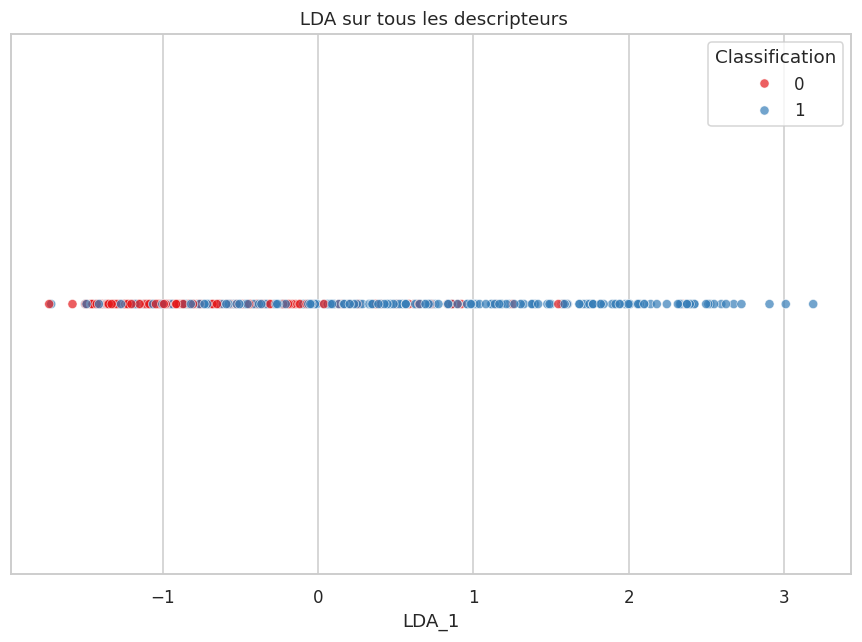

In [5]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y=np.zeros(len(df_lda)),
        hue='Classification', palette='Set1', alpha=0.7
    )
    plt.ylabel('')
    plt.yticks([])
else:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y='LDA_2',
        hue='Classification', palette='Set1', alpha=0.7
    )
plt.title(' LDA sur tous les descripteurs')
plt.tight_layout()
plt.show()

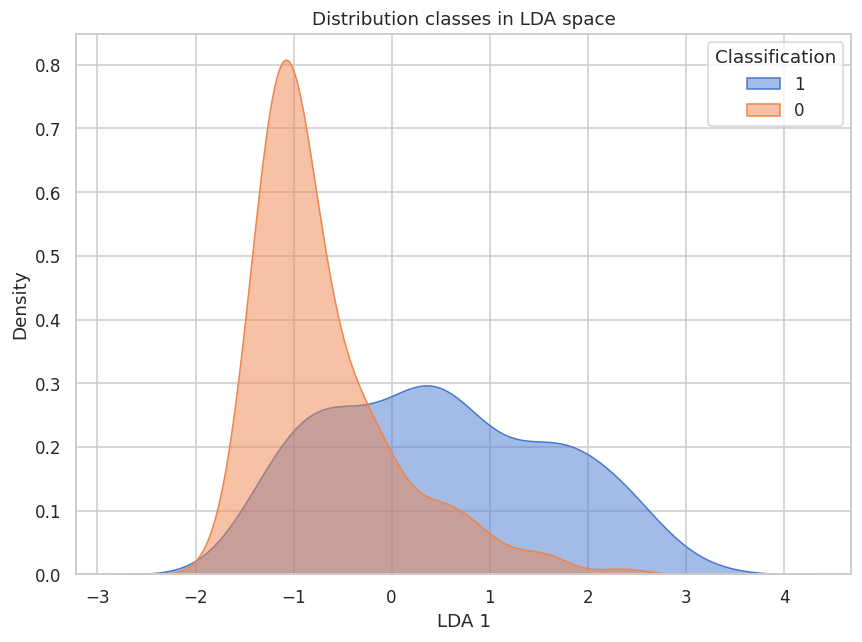

In [6]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(df_lda[df_lda['Classification'] == cls]['LDA_1'], label=cls, fill=True, alpha=0.5)
    plt.xlabel('LDA 1')
else:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(
            x=df_lda[df_lda['Classification'] == cls]['LDA_1'],
            y=df_lda[df_lda['Classification'] == cls]['LDA_2'],
            label=cls,
            fill=True,
            alpha=0.5
        )
    plt.xlabel('LDA 1')
    plt.ylabel('LDA 2')
plt.title('Distribution classes in LDA space')
plt.legend(title='Classification')
plt.savefig('Plots/lda/gene_expression_lda_distribution.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

In [7]:
coef_df = pd.DataFrame(lda.coef_, columns=X_all.columns).T
coef_df['max_abs_coef'] = coef_df.abs().max(axis=1)
coef_df_sorted = coef_df.sort_values('max_abs_coef', ascending=False)

print('Tableau des 10 meilleurs coefficients de la LDA :')
coef_df_sorted.head(10)

Tableau des 10 meilleurs coefficients de la LDA :


,0,max_abs_coef
Ka,1.220539,1.220539
Ks,0.218241,0.218241
Distance,0.212514,0.212514
Ka_Ks,-0.095898,0.095898


## K-means sur les cinq meilleurs descripteurs

### Selection dynamique des meilleurs descripteurs

On repart du classement `coef_df_sorted` etabli par la LDA (coefficient absolu maximal), puis on garde les premiers.


In [8]:
ranking_no_mean = coef_df_sorted[~coef_df_sorted.index.str.endswith('_Mean')]
selected_descriptors = ranking_no_mean.head(10).index.tolist()

print('Descripteurs selectionnes :')
print(selected_descriptors)

missing_descriptors = [
    column for column in selected_descriptors
    if column not in X_train.columns
]
if missing_descriptors:
    raise KeyError(f'Descripteurs absents : {missing_descriptors}')


Descripteurs selectionnes :
['Ka', 'Ks', 'Distance', 'Ka_Ks']


## Pipeline K-means par descripteur

**Hypotheses retenues pour le tableau recapitulatif** :
- Plage de K testee : 1 a 10 (un K est ignore s'il est superieur ou egal au nombre de points disponibles).
- *ARI moyen / ARI median* : mesure de stabilite. Le K-means est relance `n_stability_runs` fois avec des graines aleatoires differentes pour le meme K, puis l'ARI est calcule entre toutes les paires de partitions obtenues ; on rapporte la moyenne et la mediane de ces ARI.
- *BIC* : approximation gaussienne spherique classique (a la X-means / Pelleg & Moore), avec `p = (K-1) + K*d + 1` parametres libres (d = dimension, ici d = 1 par descripteur).
- *Partition non triviale ?* : vaut « Oui » si la plus petite taille de cluster est >= `min_cluster_size` (3 par defaut) **et** qu'aucun cluster ne depasse `max_cluster_frac` (90% par defaut) des points, « Non » sinon.
- Le K final retenu par descripteur est celui qui maximise la silhouette parmi les partitions non triviales (repli sur l'ensemble des partitions K>1 si aucune n'est non triviale).


In [9]:
from itertools import combinations

# Constantes ajustables
k_values = list(range(1, 11))
n_stability_runs = 10
min_cluster_size = 22 # 5% du nombre total de paires 
max_cluster_frac = 0.9


def compute_bic(X, labels, centers):
    """BIC approx gaussienne spherique (style X-means / Pelleg & Moore)."""
    n, d = X.shape
    k = centers.shape[0]
    n_i = np.bincount(labels, minlength=k).astype(float)

    ss = 0.0
    for i in range(k):
        pts = X[labels == i]
        if len(pts) > 0:
            ss += np.sum((pts - centers[i]) ** 2)

    dof = n - k
    if dof <= 0:
        return np.nan
    variance = ss / dof
    if variance <= 0:
        return np.nan

    log_lik = 0.0
    for i in range(k):
        if n_i[i] == 0:
            continue
        log_lik += (
            -n_i[i] / 2 * np.log(2 * np.pi)
            - n_i[i] * d / 2 * np.log(variance)
            - (n_i[i] - 1) / 2
            + n_i[i] * np.log(n_i[i])
            - n_i[i] * np.log(n)
        )

    n_params = (k - 1) + k * d + 1
    return log_lik - (n_params / 2) * np.log(n)


def kmeans_stability(X, k, n_runs, base_seed, n_init):
    """Relance le K-means n_runs fois (graines differentes) et calcule les ARI par paire."""
    labelings, inertias = [], []
    for run in range(n_runs):
        model = KMeans(n_clusters=k, n_init=n_init, random_state=base_seed + run)
        labels = model.fit_predict(X)
        labelings.append(labels)
        inertias.append(model.inertia_)
    aris = [
        adjusted_rand_score(a, b)
        for a, b in combinations(labelings, 2)
    ]
    return labelings, inertias, aris


def kmeans_grid_summary(X, k_values, n_runs=n_stability_runs, base_seed=random_state,
                         n_init=n_init, min_cluster_size=min_cluster_size,
                         max_cluster_frac=max_cluster_frac):
    """Construit le tableau recapitulatif Inertie/Silhouette/ARI/BIC pour une plage de K."""
    n = X.shape[0]
    rows = []

    for k in k_values:
        if k == 1:
            center = X.mean(axis=0, keepdims=True)
            inertia = float(np.sum((X - center) ** 2))
            rows.append({
                'K': k, 'Inertie': inertia, 'Silhouette': np.nan,
                'ARI moyen': np.nan, 'ARI median': np.nan,
                'Taille min': np.nan, 'Taille max': np.nan,
                'Partition non triviale ?': np.nan, 'BIC': np.nan
            })
            continue

        if k >= n:
            continue

        labelings, inertias, aris = kmeans_stability(X, k, n_runs, base_seed, n_init)
        best_idx = int(np.argmin(inertias))
        labels = labelings[best_idx]

        if len(set(labels)) < 2:
            continue

        sizes = np.bincount(labels, minlength=k)
        sil = silhouette_score(X, labels)

        final_model = KMeans(n_clusters=k, n_init=n_init, random_state=base_seed).fit(X)
        bic = compute_bic(X, labels, final_model.cluster_centers_)

        non_trivial = bool(
            sizes.min() >= min_cluster_size and sizes.max() / n <= max_cluster_frac
        )

        rows.append({
            'K': k,
            'Inertie': inertias[best_idx],
            'Silhouette': sil,
            'ARI moyen': float(np.mean(aris)) if aris else np.nan,
            'ARI median': float(np.median(aris)) if aris else np.nan,
            'Taille min': float(sizes.min()),
            'Taille max': float(sizes.max()),
            'Partition non triviale ?': 'Oui' if non_trivial else 'Non',
            'BIC': bic
        })

    return pd.DataFrame(rows)


### Boucle principale : premier cluster (Asymmetry) + grille K-means par descripteur


In [10]:
descriptor_summaries = {}
labels_by_descriptor = {}

X_all_scaled_df = pd.DataFrame(
    X_all_scaled,
    columns=X_all.columns,
    index=X_train.index
)

for descriptor in selected_descriptors:
    values_scaled = pd.to_numeric(
        X_all_scaled_df[descriptor],
        errors='coerce'
    )

    labels_full = pd.Series(
        index=X_train.index,
        dtype='Int64'
    )

    remaining_mask = values_scaled.notna()
    X_remaining_scaled = values_scaled.loc[
        remaining_mask
    ].to_numpy().reshape(-1, 1)

    if len(X_remaining_scaled) == 0:
        labels_by_descriptor[descriptor] = labels_full
        continue

    summary_df = kmeans_grid_summary(
        X_remaining_scaled,
        k_values
    )

    descriptor_summaries[descriptor] = summary_df

    print(f'Tableau récapitulatif K-means -- {descriptor}')
    display(summary_df)

    candidates = summary_df[summary_df['K'] > 1]
    non_trivial = candidates[
        candidates['Partition non triviale ?'] == 'Oui'
    ]

    pool = (
        non_trivial
        if not non_trivial.empty
        else candidates
    )

    if not pool.empty:
        best_row = pool.loc[
            pool['Silhouette'].idxmax()
        ]

        best_k = int(best_row['K'])

        final_model = KMeans(
            n_clusters=best_k,
            n_init=n_init,
            random_state=random_state
        )

        final_labels = final_model.fit_predict(
            X_remaining_scaled
        )

        labels_full.loc[
            values_scaled.loc[remaining_mask].index
        ] = final_labels

        print(f'K retenu pour {descriptor} : {best_k}')

    labels_by_descriptor[descriptor] = labels_full.astype('Int64')

Tableau récapitulatif K-means -- Ka


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,116.265396,0.650850,1.000000,1.000000,138.0,306.0,Oui,-619.901976
2,3,44.814539,0.640531,1.000000,1.000000,81.0,230.0,Oui,-588.611513
3,4,27.296425,0.599692,0.975384,1.000000,71.0,177.0,Oui,-1489.772119
4,5,18.323670,0.585226,0.997778,1.000000,41.0,174.0,Oui,-608.414146
5,6,13.406392,0.558952,0.887117,0.872483,38.0,150.0,Oui,-1511.472485
6,7,9.588770,0.560682,0.929991,0.896915,28.0,131.0,Oui,-1456.475256
7,8,7.684533,0.554007,0.937470,0.924093,28.0,96.0,Oui,-1303.627759
8,9,5.790354,0.556811,0.931900,0.940305,8.0,93.0,Non,-1850.598297
9,10,4.878662,0.554770,0.920018,0.918299,4.0,93.0,Non,-1594.204741


K retenu pour Ka : 2
Tableau récapitulatif K-means -- Ks


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,183.426171,0.573693,1.000000,1.000000,200.0,244.0,Oui,-751.525469
2,3,83.786871,0.643600,0.988214,0.994831,40.0,212.0,Oui,-692.258359
3,4,56.223966,0.623071,0.994410,0.991833,10.0,190.0,Non,-671.134359
4,5,36.277520,0.593748,0.961149,0.961374,1.0,180.0,Non,-662.384899
5,6,24.454204,0.602220,0.998914,1.000000,1.0,179.0,Non,-1777.619313
6,7,16.671338,0.552794,1.000000,1.000000,1.0,112.0,Non,-664.532965
7,8,12.728697,0.532621,0.875859,0.880533,1.0,104.0,Non,-1940.310456
8,9,10.007715,0.535978,0.929259,0.938055,1.0,99.0,Non,-2163.353849
9,10,7.791167,0.533822,0.933711,0.928146,1.0,91.0,Non,-1912.027100


K retenu pour Ks : 3
Tableau récapitulatif K-means -- Distance


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,145.359553,0.650947,1.000000,1.000000,107.0,337.0,Oui,-639.499734
2,3,77.611386,0.575517,1.000000,1.000000,77.0,215.0,Oui,-714.864834
3,4,37.406493,0.613652,1.000000,1.000000,26.0,197.0,Oui,-640.475491
4,5,25.637318,0.592085,0.990249,1.000000,24.0,173.0,Oui,-1570.063561
5,6,17.525917,0.601184,1.000000,1.000000,24.0,155.0,Oui,-680.628239
6,7,13.078266,0.608402,0.992510,0.993909,24.0,136.0,Oui,-1461.066065
7,8,9.696076,0.610874,0.987435,0.991463,9.0,136.0,Non,-1614.193265
8,9,7.723070,0.616463,0.992271,0.994483,9.0,127.0,Non,-652.770547
9,10,6.151680,0.601176,0.987921,0.993667,9.0,125.0,Non,-1680.830870


K retenu pour Distance : 2
Tableau récapitulatif K-means -- Ka_Ks


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,140.085037,0.626499,1.000000,1.000000,127.0,317.0,Oui,-651.871468
2,3,70.144557,0.566611,1.000000,1.000000,71.0,206.0,Oui,-690.300520
3,4,43.243284,0.545712,0.927830,0.909077,29.0,177.0,Oui,-1224.919090
4,5,27.505094,0.535135,0.957226,0.986338,23.0,138.0,Oui,-1702.418843
5,6,18.031655,0.558080,1.000000,1.000000,21.0,124.0,Non,-694.663295
6,7,14.101932,0.535287,0.953872,0.963487,21.0,90.0,Non,-739.698019
7,8,11.507586,0.538270,0.898731,0.914794,21.0,79.0,Non,-1790.179109
8,9,9.147960,0.541239,0.842425,0.821497,5.0,79.0,Non,-1669.392180
9,10,7.291061,0.547742,0.900325,0.876156,5.0,74.0,Non,-1886.542330


K retenu pour Ka_Ks : 2


### Tailles de clusters finales (premier cluster inclus)


In [11]:
X_top_5 = X_train[selected_descriptors].copy()
scaler_top_5 = StandardScaler()
X_top_5_scaled = pd.DataFrame(
    scaler_top_5.fit_transform(X_top_5),
    columns=selected_descriptors,
    index=X_top_5.index
)

cluster_size_rows = []
for descriptor, labels in labels_by_descriptor.items():
    counts = labels.value_counts().sort_index()
    for cluster, size in counts.items():
        cluster_size_rows.append({
            'Descripteur': descriptor,
            'Cluster': int(cluster),
            'Taille': int(size)
        })

cluster_sizes_df = pd.DataFrame(cluster_size_rows)
display(cluster_sizes_df)


,Descripteur,Cluster,Taille
0,Ka,0,138
1,Ka,1,306
2,Ks,0,210
3,Ks,1,195
4,Ks,2,39
5,Distance,0,337
6,Distance,1,107
7,Ka_Ks,0,127
8,Ka_Ks,1,317


In [12]:
# Comparaison en conservant les identifiants réels des clusters

y_train = pd.read_csv("Données/Y_train_clean.csv")
classifications = y_train["Classification"].reset_index(drop=True)

cluster_sizes_by_descriptor = {}
cluster_ratios_by_descriptor = {}

# position du centre des clusters 

for descriptor in selected_descriptors:
    labels = labels_by_descriptor[descriptor].reset_index(drop=True)

    if len(labels) != len(classifications):
        raise ValueError(
            f"Nombre de labels incompatible pour {descriptor}."
        )

    valid_mask = labels.notna() & classifications.notna()

    labels_valid = labels.loc[valid_mask].astype(int)
    classifications_valid = classifications.loc[valid_mask]

    cluster_sizes = {}
    cluster_ratios = {}

    # Les identifiants réels sont conservés
    for cluster_id in sorted(labels_valid.unique()):
        cluster_mask = labels_valid == cluster_id

        n_points = int(cluster_mask.sum())
        n_redondant = int(
            ((classifications_valid == 0) & cluster_mask).sum()
        )
        n_divergent = int(
            ((classifications_valid == 1) & cluster_mask).sum()
        )

        ratio = (
            n_redondant / n_divergent
            if n_divergent > 0
            else np.inf
        )

        cluster_sizes[cluster_id] = n_points
        cluster_ratios[cluster_id] = ratio

    cluster_sizes_by_descriptor[descriptor] = cluster_sizes
    cluster_ratios_by_descriptor[descriptor] = cluster_ratios


# Nombre maximal d'identifiants de clusters
max_cluster_id = max(
    max(cluster_sizes.keys())
    for cluster_sizes in cluster_sizes_by_descriptor.values()
)

columns = [
    f"Cluster {cluster_id}"
    for cluster_id in range(max_cluster_id + 1)
]

cluster_comparison = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=columns,
    dtype=float
)

ratio_comparison = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=columns,
    dtype=float
)


# Remplissage selon les identifiants réels
for descriptor in selected_descriptors:
    cluster_sizes = cluster_sizes_by_descriptor[descriptor]
    cluster_ratios = cluster_ratios_by_descriptor[descriptor]

    for cluster_id in cluster_sizes:
        column = f"Cluster {cluster_id}"

        cluster_comparison.loc[
            descriptor, column
        ] = cluster_sizes[cluster_id]

        ratio_comparison.loc[
            descriptor, column
        ] = cluster_ratios[cluster_id]


# Annotations
annot_matrix = pd.DataFrame(
    "",
    index=cluster_comparison.index,
    columns=cluster_comparison.columns,
    dtype=object
)

for descriptor in cluster_comparison.index:
    for column in cluster_comparison.columns:
        n_points = cluster_comparison.loc[descriptor, column]
        ratio = ratio_comparison.loc[descriptor, column]

        if pd.isna(n_points):
            annot_matrix.loc[descriptor, column] = ""
        else:
            ratio_text = (
                f"{ratio:.2f}"
                if not np.isinf(ratio)
                else "inf"
            )

            annot_matrix.loc[descriptor, column] = (
                f"{int(n_points)} paires\n"
                f"R/D={ratio_text}"
            )



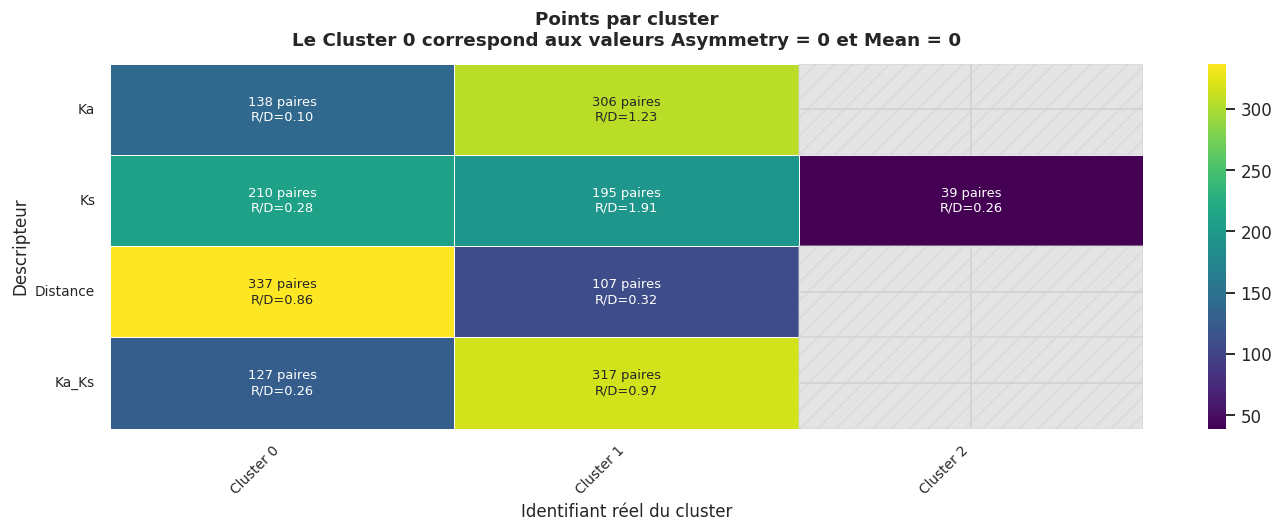

In [13]:
# Heatmap
fig, ax = plt.subplots(figsize=(13, 5))

nan_mask = cluster_comparison.isna()

sns.heatmap(
    cluster_comparison,
    annot=annot_matrix,
    fmt="",
    cmap="viridis",
    cbar=True,
    mask=nan_mask,
    linewidths=0.5,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8.5}
)

# Hachures pour les clusters absents
for row_index in range(cluster_comparison.shape[0]):
    for column_index in range(cluster_comparison.shape[1]):
        if nan_mask.iloc[row_index, column_index]:
            ax.add_patch(
                plt.Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=True,
                    color="lightgrey",
                    hatch="//",
                    alpha=0.6
                )
            )

ax.set_title(
    "Points par cluster\n"
    "Le Cluster 0 correspond aux valeurs Asymmetry = 0 et Mean = 0",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax.set_xlabel("Identifiant réel du cluster", fontsize=11)
ax.set_ylabel("Descripteur", fontsize=11)

ax.set_xticklabels(
    columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    selected_descriptors,
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [14]:
# Classement des clusters par centre décroissant pour chaque descripteur

X_all_scaled_df = pd.DataFrame(
    X_all_scaled,
    columns=X_all.columns,
    index=X_train.index
)

ordered_clusters_by_descriptor = {}
cluster_centers_by_descriptor = {}
ordered_rows = []

for descriptor in selected_descriptors:
    labels = labels_by_descriptor[descriptor]

    valid_mask = (
        labels.notna()
        & X_all_scaled_df[descriptor].notna()
    )

    values = X_all_scaled_df.loc[valid_mask, descriptor]
    labels_valid = labels.loc[valid_mask].astype(int)

    centers = values.groupby(labels_valid).mean()
    ordered_clusters = centers.sort_values(
        ascending=False
    ).index.tolist()

    ordered_clusters_by_descriptor[descriptor] = ordered_clusters
    cluster_centers_by_descriptor[descriptor] = centers

    classification_valid = classifications.loc[valid_mask]

    row_sizes = {}
    row_ratios = {}

    for cluster_id in ordered_clusters:
        cluster_mask = labels_valid == cluster_id

        n_pairs = int(cluster_mask.sum())
        n_redondant = int(
            ((classification_valid == 0) & cluster_mask).sum()
        )
        n_divergent = int(
            ((classification_valid == 1) & cluster_mask).sum()
        )

        ratio = (
            n_redondant / n_divergent
            if n_divergent > 0
            else np.inf
        )

        row_sizes[cluster_id] = n_pairs
        row_ratios[cluster_id] = ratio

    ordered_rows.append({
        "descriptor": descriptor,
        "clusters": ordered_clusters,
        "sizes": row_sizes,
        "ratios": row_ratios
    })


# Nombre maximal de clusters
max_clusters = max(
    len(row["clusters"])
    for row in ordered_rows
)

rank_columns = [
    f"Rang {rank}"
    for rank in range(1, max_clusters + 1)
]

cluster_comparison_ordered = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=rank_columns,
    dtype=float
)

annotations_ordered = pd.DataFrame(
    "",
    index=selected_descriptors,
    columns=rank_columns,
    dtype=object
)

cluster_labels_ordered = pd.DataFrame(
    "",
    index=selected_descriptors,
    columns=rank_columns,
    dtype=object
)


for row in ordered_rows:
    descriptor = row["descriptor"]

    for rank, cluster_id in enumerate(row["clusters"]):
        column = f"Rang {rank + 1}"

        n_pairs = row["sizes"][cluster_id]
        ratio = row["ratios"][cluster_id]
        center = cluster_centers_by_descriptor[
            descriptor
        ].loc[cluster_id]

        cluster_comparison_ordered.loc[
            descriptor, column
        ] = n_pairs

        cluster_labels_ordered.loc[
            descriptor, column
        ] = f"Cluster {cluster_id}"

        ratio_text = (
            f"{ratio:.2f}"
            if not np.isinf(ratio)
            else "inf"
        )

        annotations_ordered.loc[
            descriptor, column
        ] = (
            f"Cluster {cluster_id}\n"
            f"{n_pairs} paires\n"
            f"R/D={ratio_text}"
        )


# Affichage de l'ordre des centres
centers_ordered_df = pd.DataFrame(
    {
        descriptor: pd.Series(
            cluster_centers_by_descriptor[descriptor]
            .sort_values(ascending=False)
            .values
        )
        for descriptor in selected_descriptors
    }
)

display(centers_ordered_df)

,Ka,Ks,Distance,Ka_Ks
0,1.279354,2.192727,1.455479,1.307111
1,-0.576964,0.384269,-0.462125,-0.523669
2,NaN,-0.852374,NaN,NaN


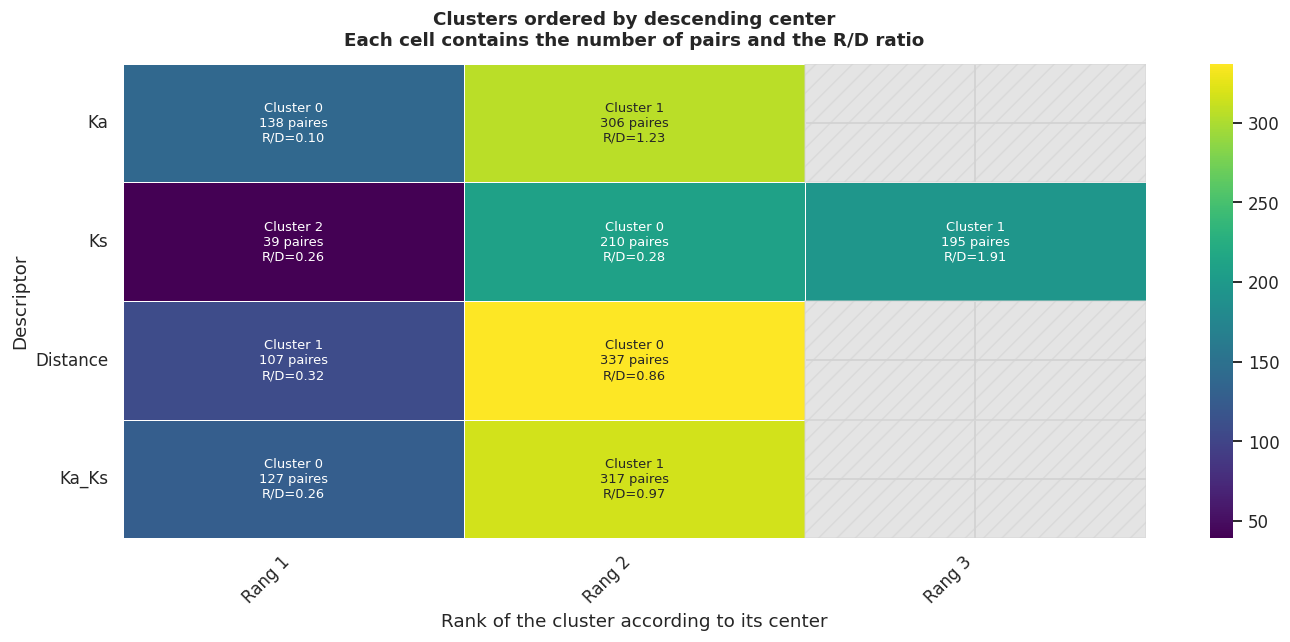

In [15]:
# Heatmap du nombre de paires
fig, ax = plt.subplots(figsize=(13, 6))

nan_mask = cluster_comparison_ordered.isna()

sns.heatmap(
    cluster_comparison_ordered,
    annot=annotations_ordered,
    fmt="",
    cmap="viridis",
    cbar=True,
    mask=nan_mask,
    linewidths=0.5,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8.5}
)

# Hachures pour les rangs inexistants
for row_index in range(
    cluster_comparison_ordered.shape[0]
):
    for column_index in range(
        cluster_comparison_ordered.shape[1]
    ):
        if nan_mask.iloc[row_index, column_index]:
            ax.add_patch(
                plt.Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=True,
                    color="lightgrey",
                    hatch="//",
                    alpha=0.6
                )
            )

ax.set_title(
    "Clusters ordered by descending center\n"
    "Each cell contains the number of pairs and the R/D ratio",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax.set_xlabel(
    "Rank of the cluster according to its center"
)
ax.set_ylabel("Descriptor")

ax.set_xticklabels(
    rank_columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    selected_descriptors,
    rotation=0
)

plt.tight_layout()
plt.show()

## Matrices d'adjacences

In [16]:
family_adjacency_matrices = {}

for family_name in X_top_5_scaled.columns:

    if family_name == "Ks":
        optimal_k = 3
    else:
        optimal_k = 2

    X_family = X_top_5_scaled[[family_name]]

    kmeans_family = KMeans(
        n_clusters=optimal_k,
        n_init=n_init,
        random_state=random_state,
        init="k-means++"
    )

    labels_family = kmeans_family.fit_predict(X_family)

    Z_family_binary = pd.get_dummies(labels_family).astype(int)

    adjacency_matrix = (
        Z_family_binary.values @ Z_family_binary.values.T
    )

    np.fill_diagonal(adjacency_matrix, 0)

    family_adjacency_matrices[family_name] = adjacency_matrix

    print(
        f"{family_name} : {adjacency_matrix.shape}, "
        f"{adjacency_matrix.sum() / 2:.0f} paires"
    )

Ka : (444, 444), 56118 paires
Ks : (444, 444), 41601 paires
Distance : (444, 444), 62287 paires
Ka_Ks : (444, 444), 58087 paires


In [17]:
for family_name, adjacency_matrix in family_adjacency_matrices.items():

    adjacency_df = pd.DataFrame(
        adjacency_matrix,
        index=X_top_5_scaled.index,
        columns=X_top_5_scaled.index
    )

    adjacency_df.to_csv(
        f"Données/adjacency/lda/family/adjacency_matrix_silh_{family_name}.csv"
    )

    print(f"Matrice sauvegardée pour : {family_name}")

Matrice sauvegardée pour : Ka
Matrice sauvegardée pour : Ks
Matrice sauvegardée pour : Distance
Matrice sauvegardée pour : Ka_Ks


### Matrice agrégées

In [18]:
family_groups = {"KaKs" : ["Ka", "Ks", "Ka_Ks", 
                           "Ks_SD", "Ka_SD", "Distance"]
}

group_adjacency_matrices = {}

for group_name, descriptors in family_groups.items():

    available_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in family_adjacency_matrices
    ]

    if not available_descriptors:
        print(f"Aucune matrice disponible pour {group_name}")
        continue

    group_matrix = np.sum(
        [
            family_adjacency_matrices[descriptor]
            for descriptor in available_descriptors
        ],
        axis=0
    )

    group_adjacency_matrices[group_name] = group_matrix

    print(
        f"{group_name} : "
        f"{available_descriptors} -> {group_matrix.shape}"
    )

KaKs : ['Ka', 'Ks', 'Ka_Ks', 'Distance'] -> (444, 444)


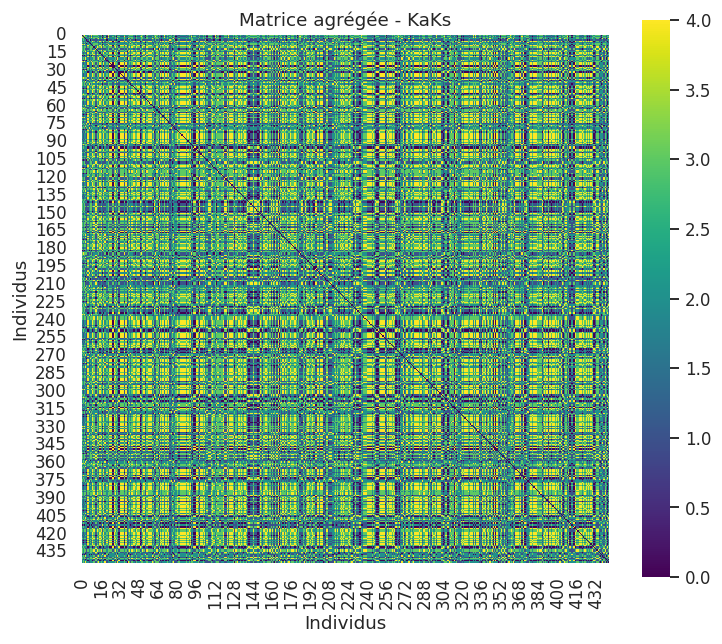

In [19]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

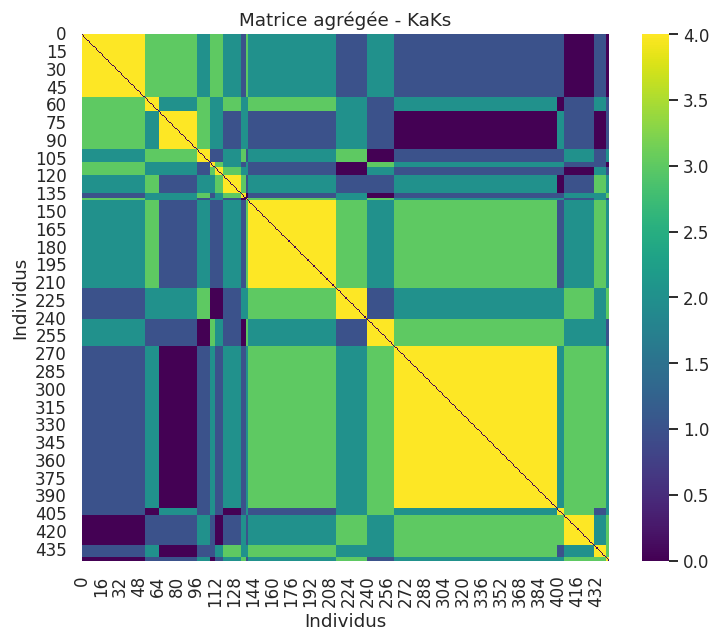

In [20]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

cluster_label_matrix = np.column_stack([
    labels_by_descriptor[descriptor]
    .reset_index(drop=True)
    .fillna(-1)
    .astype(int)
    .to_numpy()
    for descriptor in selected_descriptors
])
ordered_indices = np.lexsort(cluster_label_matrix[:, ::-1].T)

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    ordered_adjacency = matrix[np.ix_(ordered_indices, ordered_indices)]

    sns.heatmap(ordered_adjacency, ax=ax, cmap='viridis', cbar=True)

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

KaKs : ['Ka'] -> (444, 444)


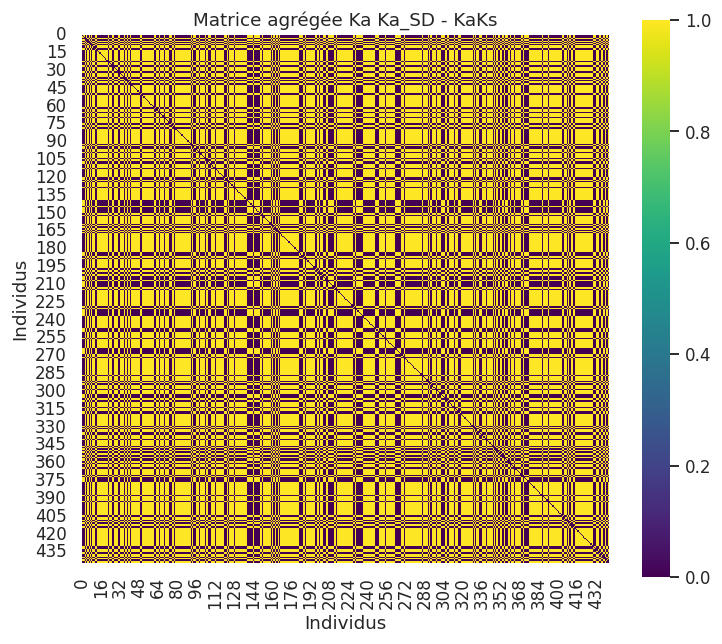

In [21]:
family_groups = {"KaKs" : ["Ka", "Ka_SD"]
}

group_adjacency_matrices = {}

for group_name, descriptors in family_groups.items():

    available_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in family_adjacency_matrices
    ]

    if not available_descriptors:
        print(f"Aucune matrice disponible pour {group_name}")
        continue

    group_matrix = np.sum(
        [
            family_adjacency_matrices[descriptor]
            for descriptor in available_descriptors
        ],
        axis=0
    )

    group_adjacency_matrices[group_name] = group_matrix

    print(
        f"{group_name} : "
        f"{available_descriptors} -> {group_matrix.shape}"
    )
    fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée Ka Ka_SD - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

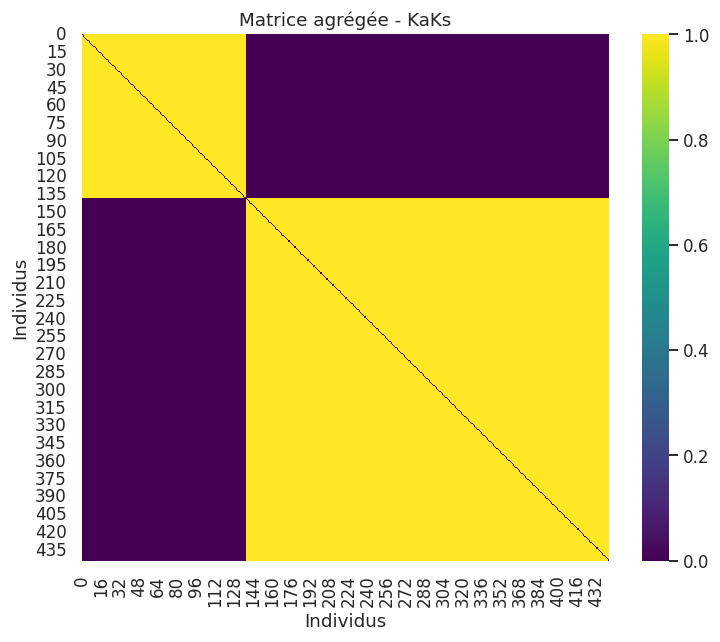

In [22]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

cluster_label_matrix = np.column_stack([
    labels_by_descriptor[descriptor]
    .reset_index(drop=True)
    .fillna(-1)
    .astype(int)
    .to_numpy()
    for descriptor in selected_descriptors
])
ordered_indices = np.lexsort(cluster_label_matrix[:, ::-1].T)

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    ordered_adjacency = matrix[np.ix_(ordered_indices, ordered_indices)]

    sns.heatmap(ordered_adjacency, ax=ax, cmap='viridis', cbar=True)

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

KaKs : ['Ks'] -> (444, 444)


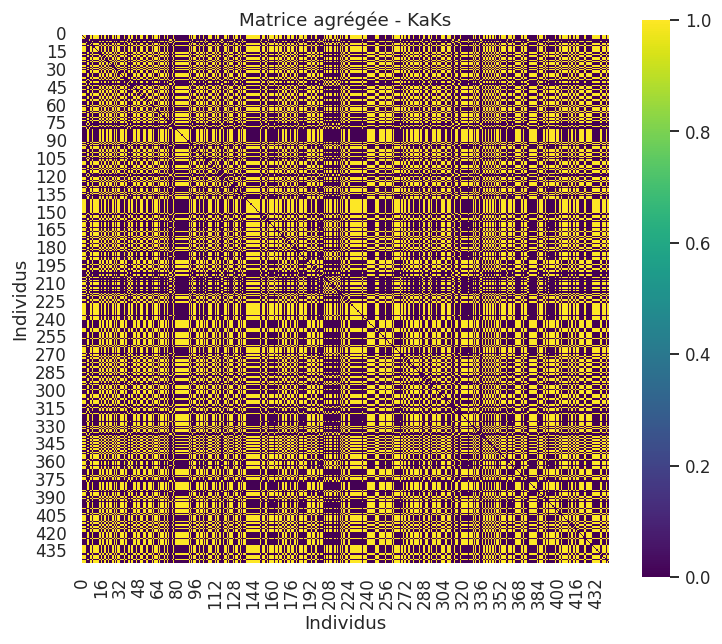

In [23]:
family_groups = {"KaKs" : ["Ks", "Ks_SD"]
}

group_adjacency_matrices = {}

for group_name, descriptors in family_groups.items():

    available_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in family_adjacency_matrices
    ]

    if not available_descriptors:
        print(f"Aucune matrice disponible pour {group_name}")
        continue

    group_matrix = np.sum(
        [
            family_adjacency_matrices[descriptor]
            for descriptor in available_descriptors
        ],
        axis=0
    )

    group_adjacency_matrices[group_name] = group_matrix

    print(
        f"{group_name} : "
        f"{available_descriptors} -> {group_matrix.shape}"
    )
    fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

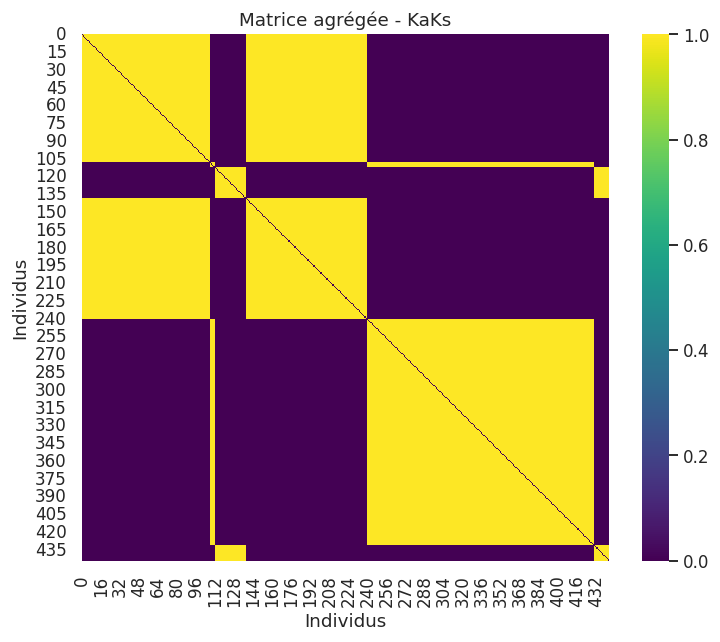

In [24]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

cluster_label_matrix = np.column_stack([
    labels_by_descriptor[descriptor]
    .reset_index(drop=True)
    .fillna(-1)
    .astype(int)
    .to_numpy()
    for descriptor in selected_descriptors
])
ordered_indices = np.lexsort(cluster_label_matrix[:, ::-1].T)

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    ordered_adjacency = matrix[np.ix_(ordered_indices, ordered_indices)]

    sns.heatmap(ordered_adjacency, ax=ax, cmap='viridis', cbar=True)

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

In [25]:
family_groups = {"KaKs" : ["Ka", "Ks", "Ka_Ks"]
}

group_adjacency_matrices = {}

for group_name, descriptors in family_groups.items():

    available_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in family_adjacency_matrices
    ]

    if not available_descriptors:
        print(f"Aucune matrice disponible pour {group_name}")
        continue

    group_matrix = np.sum(
        [
            family_adjacency_matrices[descriptor]
            for descriptor in available_descriptors
        ],
        axis=0
    )

    group_adjacency_matrices[group_name] = group_matrix

    print(
        f"{group_name} : "
        f"{available_descriptors} -> {group_matrix.shape}"
    )

KaKs : ['Ka', 'Ks', 'Ka_Ks'] -> (444, 444)


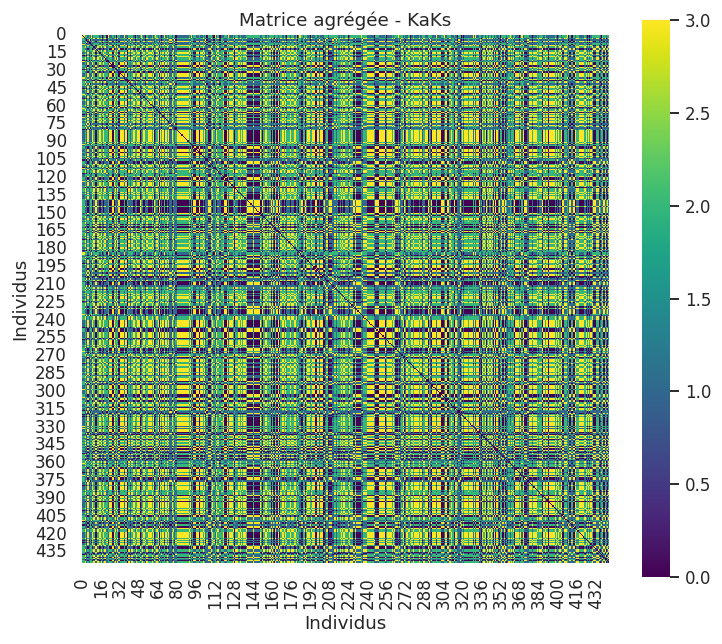

In [26]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

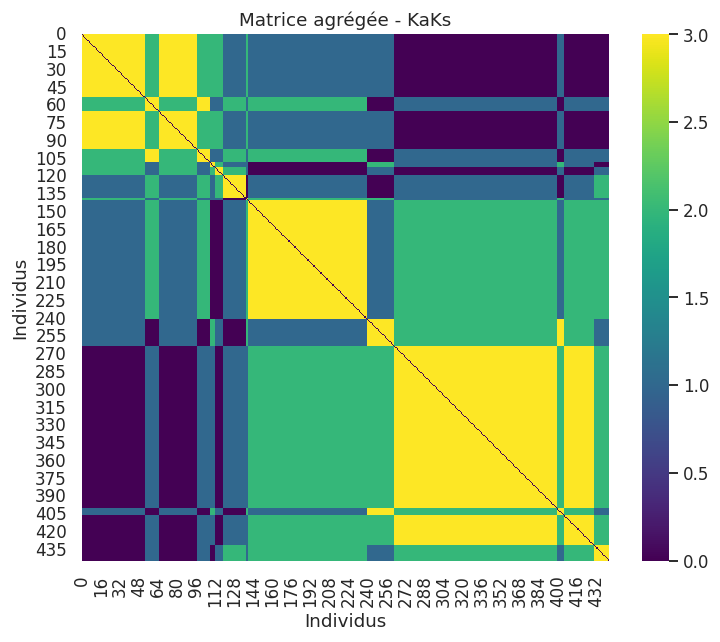

In [27]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

cluster_label_matrix = np.column_stack([
    labels_by_descriptor[descriptor]
    .reset_index(drop=True)
    .fillna(-1)
    .astype(int)
    .to_numpy()
    for descriptor in selected_descriptors
])
ordered_indices = np.lexsort(cluster_label_matrix[:, ::-1].T)

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    ordered_adjacency = matrix[np.ix_(ordered_indices, ordered_indices)]

    sns.heatmap(ordered_adjacency, ax=ax, cmap='viridis', cbar=True)

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

In [28]:
# Additionner les matrices d'adjacence de toutes les descripteurs et compter les nombres dans la matrice résultante
total_adjacency_sum = np.zeros_like(list(family_adjacency_matrices.values())[0])
for adjacency_matrix in family_adjacency_matrices.values():
    total_adjacency_sum += adjacency_matrix

num_zeros = (np.sum(total_adjacency_sum == 0)  - 444 )/ 2 # Nb paires de points  même cluster pour exactement 0 descripteurs
num_ones = np.sum(total_adjacency_sum == 1) / 2 # Nb paires de points même cluster pour exactement 1 descripteur
num_twos = np.sum(total_adjacency_sum == 2) / 2 # Nb paires de points même cluster pour exactement 2 descripteurs
num_threes = np.sum(total_adjacency_sum == 3) / 2 # Nb paires de points même cluster pour exactement 3 descripteurs
num_fours = np.sum(total_adjacency_sum == 4) / 2 # Nb paires de points même cluster pour exactement 4 descripteurs
num_fives = np.sum(total_adjacency_sum == 5) / 2 # Nb paires de points même cluster pour exactement 5 descripteurs

print(f"Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: {num_zeros:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 1 descripteur: {num_ones:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 2 descripteurs: {num_twos:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: {num_threes:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: {num_fours:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: {num_fives:.0f}")

Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: 7176
Nombre de paires de points dans le même cluster pour exactement 1 descripteur: 21844

Nombre de paires de points dans le même cluster pour exactement 2 descripteurs: 26821
Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: 27413
Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: 15092
Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: 0


In [29]:
num_twos + num_threes + num_ones + num_zeros + num_fours + num_fives

np.float64(98346.0)

In [30]:
print("\nDistribution des valeurs dans la matrice :")
total_count = 0
total_pairs = (total_adjacency_sum.size - 444) / 2

for v in range(len(selected_descriptors) + 1):
    if v == 0:
        count = np.sum(total_adjacency_sum == v) - 444
        count = count / 2
    else:
        count = np.sum(total_adjacency_sum == v) / 2

    pct = 100 * count / total_pairs
    print(f"  Valeur {v} : {int(count):,} paires ({pct:.1f}%)")
    total_count += count



Distribution des valeurs dans la matrice :
  Valeur 0 : 7,176 paires (7.3%)
  Valeur 1 : 21,844 paires (22.2%)
  Valeur 2 : 26,821 paires (27.3%)
  Valeur 3 : 27,413 paires (27.9%)
  Valeur 4 : 15,092 paires (15.3%)
